# Learning Unit 8: Implicit Neural Representations
## Denoising and Registration


Implicit neural representations aim to represent a singular data instance, i.e. an image in our case, as a continuous function. This function is represented with a neural network, that gets coordinates as input and is optimized to return the image values at that cooordinate. In short, we seek to parameterize a greyscale image $f(x)$ with pixel coordinates $x$ with a neural network $\Phi$ such that $\mathcal{L}=\int\int_{\Omega} \lVert \Phi(\mathbf{x}) - f(\mathbf{x}) \rVert\mathrm{d}\mathbf{x}$ is minimized ($\Omega$ being the domain of the image).


Different from other networks an tasks, an INR network is not trained on a larger training dataset, but should explicitly overfit on that singular data instance.


In [28]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
# download needed images and files
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
# load image
!wget -nc https://cloud.imi.uni-luebeck.de/s/fBnwQNLWXNDqsj5/download -O ct_image_pytorch.pth
!wget -nc https://cloud.imi.uni-luebeck.de/s/Njgp9L78KDkJXFj/download -O images_flow.pth

import torch
from matplotlib import pyplot as plt
from matplotlib import colors as mcolors
from IPython.display import clear_output, display

File ‘ct_image_pytorch.pth’ already there; not retrieving.
File ‘images_flow.pth’ already there; not retrieving.


In [29]:
def normalize(img):
    return (img - img.min()) / (img.max() - img.min())

## Task 1: Reconstruction
The first part will be to represent the following image with a simple network.

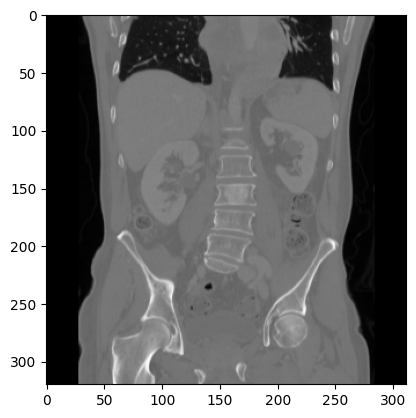

In [30]:
img = torch.load('ct_image_pytorch.pth').squeeze()
plt.imshow(img, cmap='gray')

### Task 1.1 Siren implementation

For the implicit neural representation we will make use of the [Siren](https://vsitzmann.github.io/siren/) architecture, which is a fully connected neural network with periodic activations.

Implement the Siren network architecture. The network always has a first linear layer, a last one, and  hidden layers. The hidden layers are all the same and consist of a linear layer followed by a sine activation function. The last linear layer has no activation. Use `torch.nn.Linear` and `torch.sin`.


In [31]:

class Siren(nn.Module):
    def __init__(self,in_features, out_features, hidden_ch=256,num_layers=3):
        super().__init__()
        self.scale = 30
        # TODO: initialize the first linear layer
        listnet = [nn.Linear(in_features, hidden_ch)]
        # TODO: initialize the hidden layers
        for i in range(num_layers):
          listnet.append(nn.Linear(hidden_ch, hidden_ch))
        listnet.append(nn.Linear(hidden_ch, out_features))

        self.net = nn.Sequential(*listnet)
    def forward(self,x):
        # TODO: apply the sine function to all the layers multiplied with the scaling factor except the last one
        for i in range(len(self.net)-1):
            x = torch.sin(self.scale * self.net[i](x))
        # TODO: apply the last linear layer
        x = self.net[-1](x)
        return x



Furthermore, implement a function that initializes the weights of the linear layers.
- The first layer should be initialized with a uniform distribution in the range [-1/fan_out, 1/fan_out]
- The hidden layers should be initialized with a uniform distribution in the range [- sqrt(6/fan_out)/scale, sqrt(6/fan_out)/scale]

[Documentation](https://pytorch.org/docs/stable/nn.init.html)

In [32]:
def weights_init(m):
    scale = 30
    with torch.no_grad():
        if isinstance(m, nn.Linear):
            fan_out = m.weight.shape[1]
            if m.weight.shape[1]>4:
                val = np.sqrt(6/fan_out)/scale
            else:
                val = 1/fan_out

            # Todo: initialize the weights with uniform distribution between -val and val
            torch.nn.init.uniform_(m.weight, -val, val)
            # initialize the bias with zeros
            if m.bias is not None:
                torch.nn.init.zeros_(m.bias)


Test your implementation of the Siren Network with the following: settings in_features = 1, hidden_features = 64, hidden_layers = 3, out_features = 1

Call `weights_init` on your network using `.apply` ([Doc](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.apply)).

The Network you have implemented should have ~12673 parameters.

In [33]:
#TODO: initialize the network
net = Siren(in_features=1, out_features=1,hidden_ch=64, num_layers=3)
print(net)

net.apply(weights_init)
# print number of parameters
def num_params(model):
    return sum([np.prod(p.size()) for p in model.parameters()])

print('Parameters:', num_params(net))

Siren(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parameters: 12673


### Task 1.2 Coordinate grid

Since the input to the Siren network are coordinates, write a function that returns a grid of coordinates for a given size $H\times W$. The coordinate values should be between -1 and 1.

You can do that by using `torch.mehsgrid`, `torch.linspace` and `torch.stack`.
Alternatively, you can do that in one step using `torch.nn.functional.affine_grid` and `torch.eye`.

The grid should be reshaped to a vector of shape $N\times 2$, where $N$ ist the number of pixels in the image (use `.view`).

In [34]:
# function (H,W): create coordinate grid of size HxW
def create_grid(H,W):
  theta = torch.eye(2,3).unsqueeze(0)
  grid = F.affine_grid(theta, (1,1,H,W), align_corners=True)
  return grid.view(-1,2)

torch.Size([10000, 2])


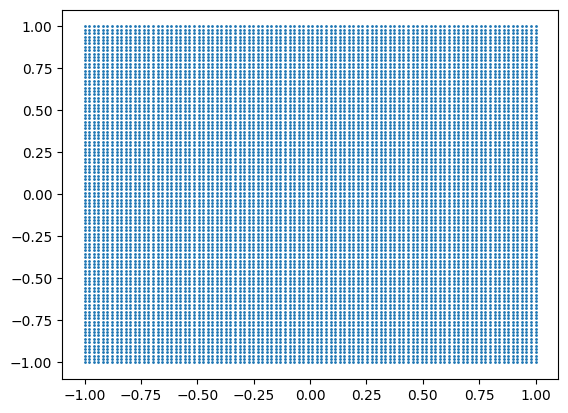

In [35]:
coords = create_grid(100,100)
print(coords.shape)
plt.scatter(coords[:, 0], coords[:, 1], s=1.)

### Task 1.3 Training
Now you can implement the training routine to reconstruct the image. The loss function should be the mean squared error between the predicted and the ground truth image.

Parameters: 198401
Iteration 0    Loss 0.1718


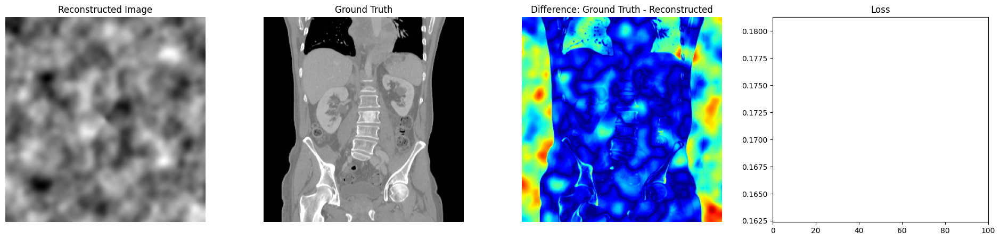

Iteration 10    Loss 0.1295


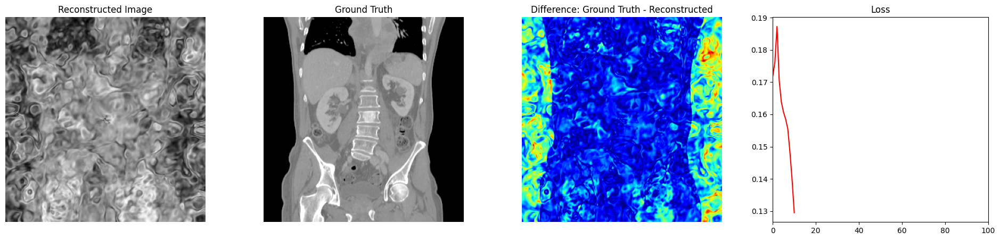

Iteration 20    Loss 0.0134


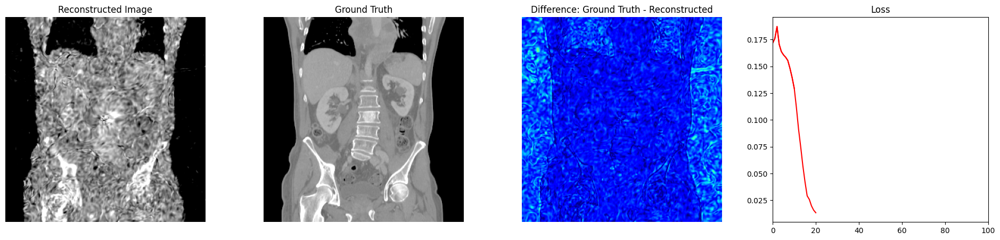

Iteration 30    Loss 0.0037


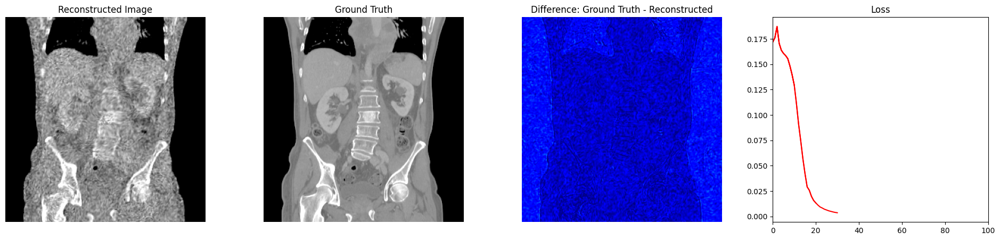

Iteration 40    Loss 0.0015


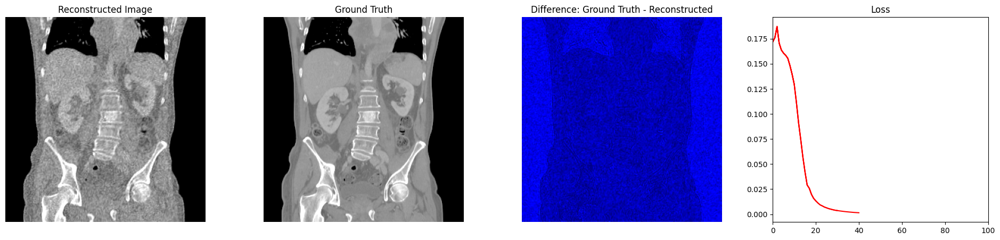

Iteration 50    Loss 0.0007


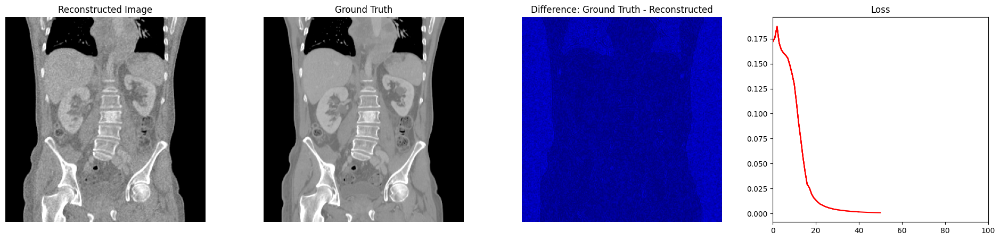

Iteration 60    Loss 0.0003


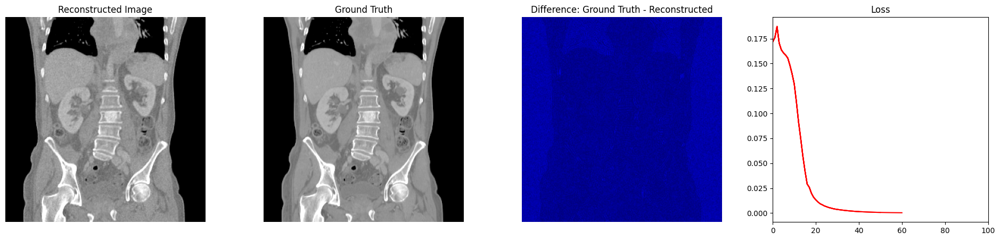

Iteration 70    Loss 0.0002


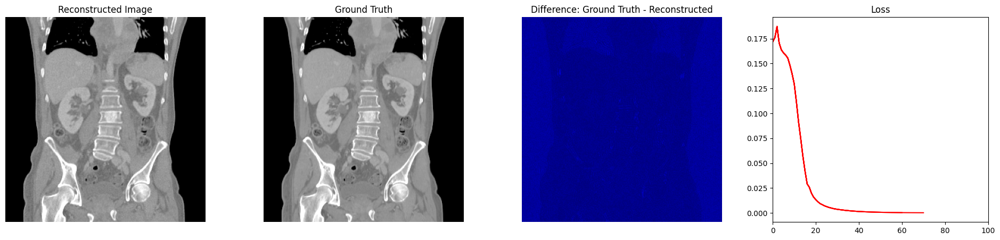

Iteration 80    Loss 0.0001


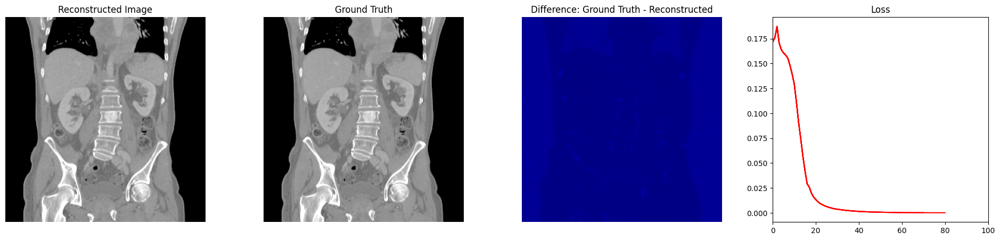

Iteration 90    Loss 0.0001


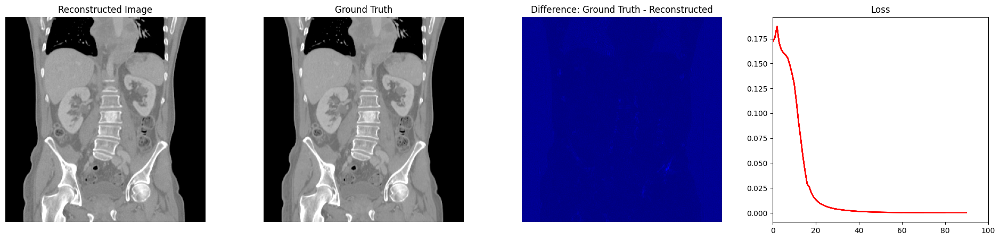

Iteration 99    Loss 0.0004


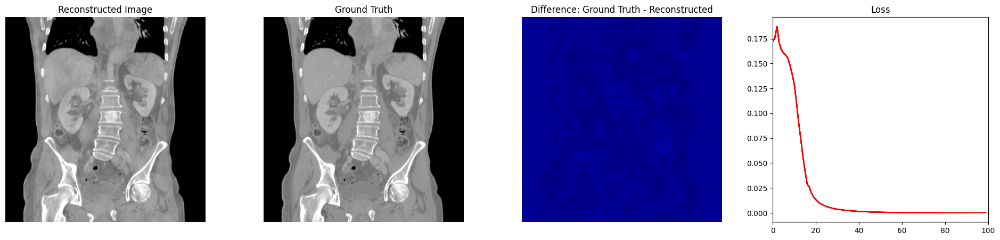

In [36]:
num_iters = 100
lr = 0.001
scale = img.max()
img_normed = img/scale
img_normed = img_normed.cuda()

# Todo: create a 2D grid of coordinates with the same size as the image
H,W =img.shape
coords = create_grid(H,W).cuda()

# Todo: create a Siren Network with the following settings
# in_features = 2, hidden_features = 256, hidden_layers = 3, out_features = 1
# The Network you have implemented should have ~198401 parameters
net = Siren(in_features=2, out_features=1, hidden_ch=256, num_layers=3).cuda()
print('Parameters:', num_params(net))


# Todo: initialize the weights of the network
net.apply(weights_init)

# Todo: initialize the optimizer with the parameters of the network and a learning rate of 1e-3
optimizer = torch.optim.Adam(lr=lr, params=net.parameters())


# plotting
fig, ax = plt.subplots(1, 4, figsize=(24, 5))
labels = ['Reconstructed Image', 'Ground Truth', 'Difference: Ground Truth - Reconstructed', 'Loss']
for i in range(4):
    ax[i].set_title(labels[i])
    if i != 3:
        ax[i].set_axis_off()
ax[3].set_xlim(0, num_iters)


# statistics
running_loss = []

for i in range(num_iters):

    # Todo: reset the gradients of the optimizer
    optimizer.zero_grad()

    # Todo: forward pass of the network
    prediction = net(coords)

    # Todo: calculate the loss
    loss= F.mse_loss(prediction, img_normed.reshape(-1,1))

    loss.backward()
    optimizer.step()

    # Todo: backward pass and update the weights

    running_loss.append(loss.item())

    if i % 10 == 0 or i == num_iters - 1:
        print('Iteration %d    Loss %.4f' % (i, loss.item()))
        ax[0].imshow(torch.clamp(prediction.detach().cpu().reshape(H, W) * scale, -500, 500), cmap='gray')
        ax[1].imshow(torch.clamp(img, -500, 500), cmap='gray')
        ax[2].imshow((normalize(img) - normalize(prediction.detach().cpu().reshape(H, W) * scale)).abs(), vmin=0, vmax=1, cmap='jet')
        ax[3].plot(running_loss, 'r')
        display(fig); plt.close()

plt.show()

### Why the periodic activation function?
In other networks ReLU, sigmoid or tanh are very common activation function. For INRs this however bears some problems.
The coordinate input for nearby voxels differs only slightly. When applying only linear layers and those activations, we can also only obtain a smooth curve as output. This prohibits us from representing higher-dimensional properties (e.g. edges) of the image properly.

To demonstrate the difference, create a class `MLP` that is identical to the `Siren` class except for the nonlinearity: Use `F.relu` instead of the scaled sinus function. Then just copy the training above and use the simple MLP+ReLU network instead of the siren network. You'll see the simple ReLU network doesn't have the capacity to represent high-dimensional features and only finds an extremely low-dimensional fit for the image.

Parameters: 198401
Iteration 0    Loss 0.1709


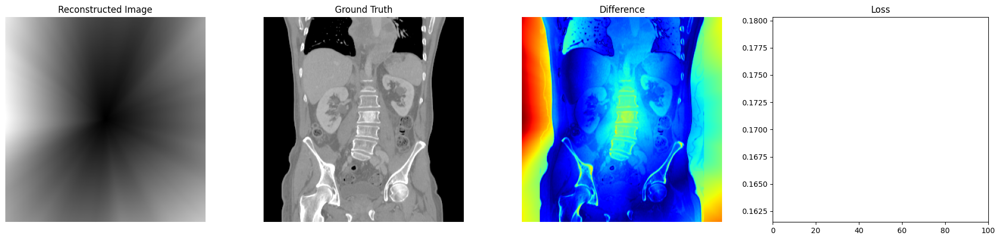

Iteration 10    Loss 0.1167


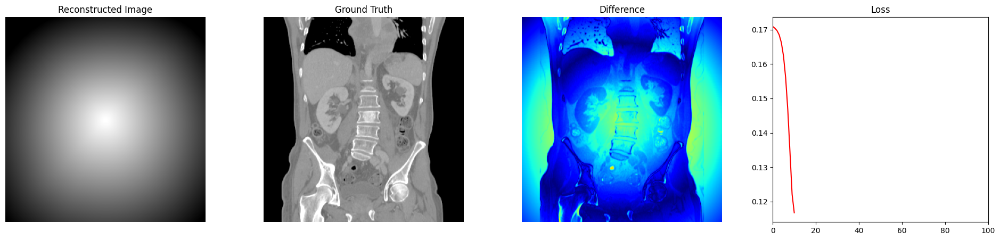

Iteration 20    Loss 0.1044


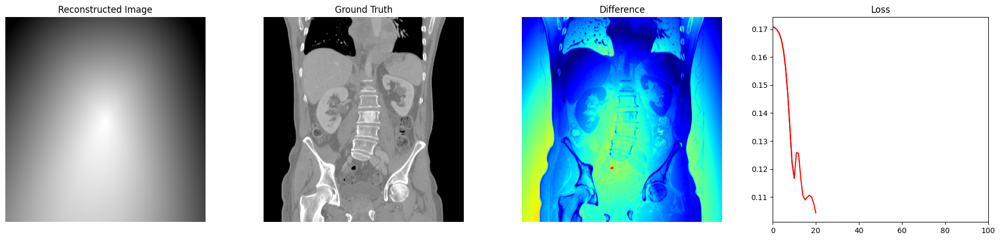

Iteration 30    Loss 0.0847


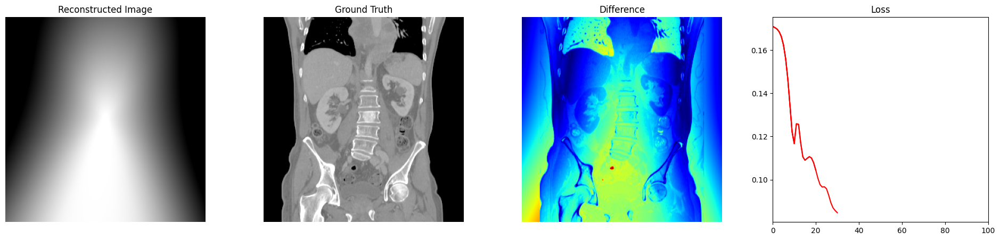

Iteration 40    Loss 0.0696


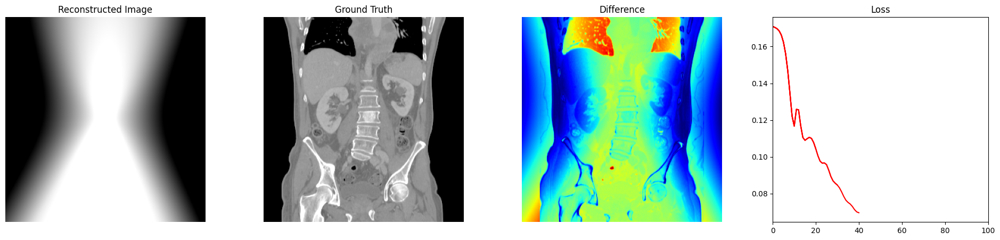

Iteration 50    Loss 0.0634


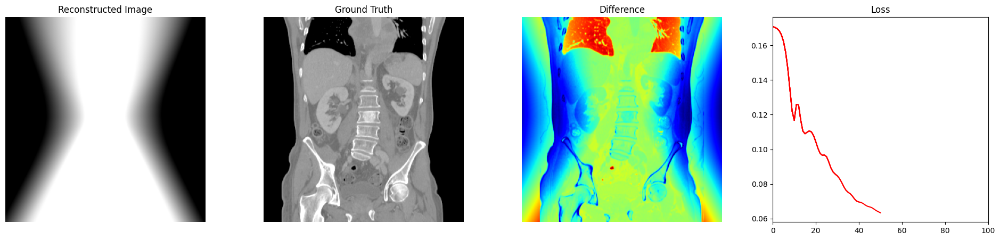

Iteration 60    Loss 0.0545


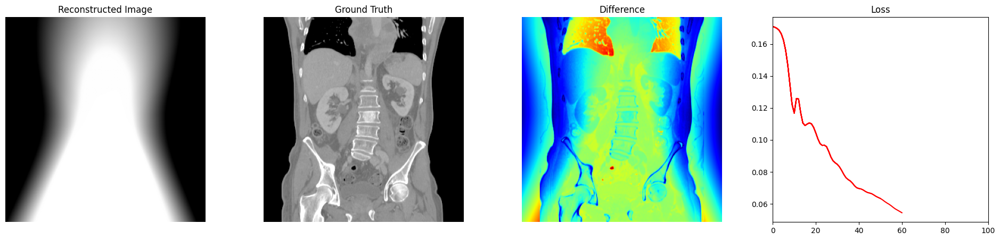

Iteration 70    Loss 0.0458


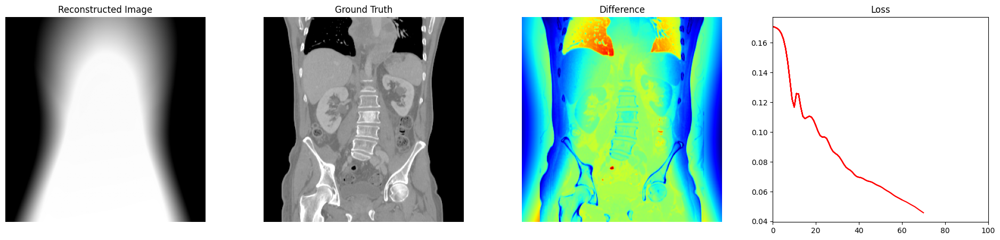

Iteration 80    Loss 0.0390


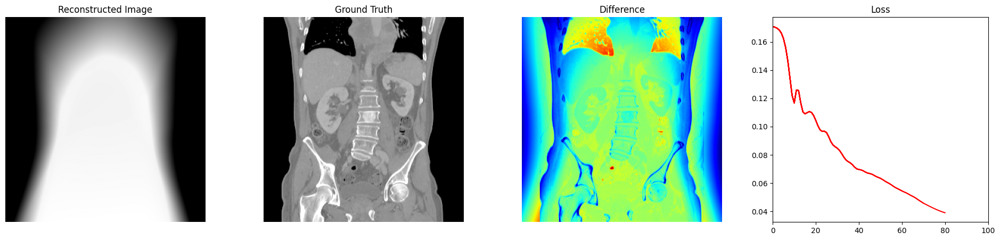

Iteration 90    Loss 0.0358


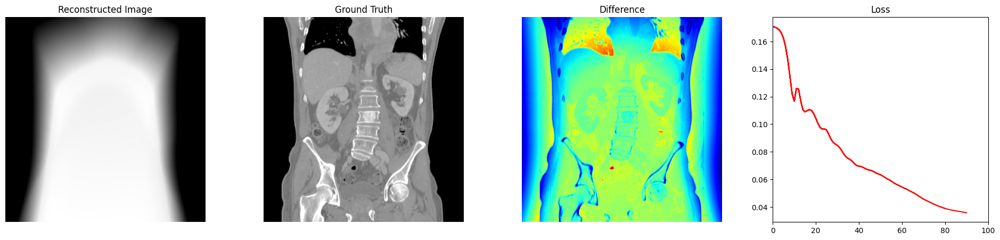

Iteration 99    Loss 0.0338


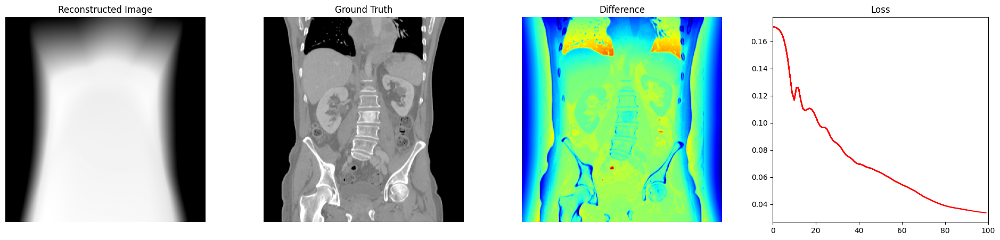

In [37]:
class MLP(Siren):
    def forward(self,x):
        #TODO: Remove the sinusoidal activation from Siren and change them to F.relu
        for i in range(len(self.net)-1):
          x = F.relu(self.net[i](x))
        x = self.net[-1](x)
        return x


#TODO: copy the training from above and change Siren to MLPr
num_iters = 100
lr = 0.001
scale=img.max()
img_normed = img/scale
img_normed = img_normed.cuda()
H,W = img.shape
coords= create_grid(H,W).cuda()
net = MLP(in_features=2, out_features=1, hidden_ch=256, num_layers=3).cuda()
print('Parameters:', num_params(net))

net.apply(weights_init)
optimizer = torch.optim.Adam(lr=lr, params=net.parameters())
fig, ax = plt.subplots(1,4, figsize=(24,5))
labels=['Reconstructed Image', 'Ground Truth', 'Difference', 'Loss']
for i in range(4):
  ax[i].set_title(labels[i])
  if i != 3:
    ax[i].set_axis_off()
ax[3].set_xlim(0, num_iters)

running_loss = []
for i in range(num_iters):
  optimizer.zero_grad()
  prediction = net(coords)
  loss = F.mse_loss(prediction, img_normed.reshape(-1,1))
  loss.backward()
  optimizer.step()
  running_loss.append(loss.item())

  if i == num_iters-1 or i % 10 ==0:
    print('Iteration %d    Loss %.4f' % (i, loss.item()))
    ax[0].imshow(torch.clamp(prediction.detach().cpu().reshape(H,W) * scale, -500, 500), cmap='gray')
    ax[1].imshow(torch.clamp(img, -500, 500), cmap='gray')
    ax[2].imshow((normalize(img) - normalize(prediction.detach().cpu().reshape(H, W) * scale)).abs(), vmin=0, vmax=1, cmap='jet')
    ax[3].plot(running_loss, 'r')
    display(fig)
    plt.close()

plt.show()

# Results Summary


1.   The siren fits the CT image and loss drops from 0.17 to 0.0001 within 100 iterations. The difference is approximately 0 everywhere.
2.   ReLu MLP only reaches a loss of 0.034 and generates a blurry image withour fine structures. Sine activations reresent edges and high frequency detail.



### Other approaches
Aside from Siren, there are further approaches to properly represent higher-dimensional images. Other activation functions than sinusoidals, e.g. [wavelets](https://openaccess.thecvf.com/content/CVPR2023/papers/Saragadam_WIRE_Wavelet_Implicit_Neural_Representations_CVPR_2023_paper.pdf) or gaussians, can work. Furthermore, instead of changing the activation function, one can directly transform the input through e.g. a [fourier feature mapping](https://arxiv.org/pdf/2006.10739) or hashing.

You can go to the linked INR playground in Moodle and try out different configurations.

## Task 2: Denoising
We now want to use the Siren network to not only reconstruct an image but also remove added noise from it. To achieve that, we add another loss term to our routine that penalizes noise.

Text(0.5, 1.0, 'Noisy image')

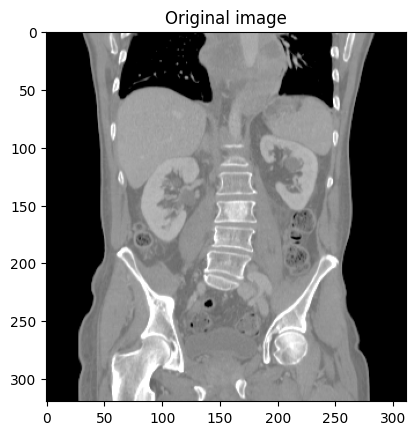

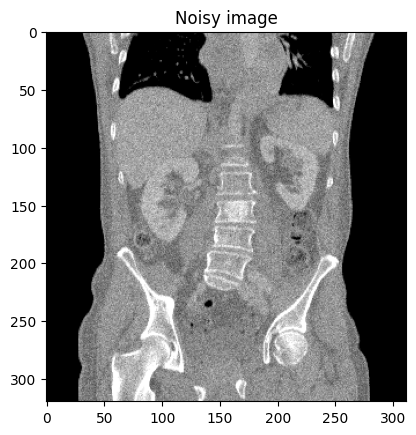

In [38]:
# helper functions to add noise to the image
def add_noise(img, sigma):
    # add noise to the image
    noise = torch.randn_like(img) * sigma
    return img + noise


# plot the input image
plt.figure()
plt.imshow(torch.clamp(img, -500, 500), cmap='gray')
plt.title('Original image')
# add noise to the image
noisy_img = add_noise(img, 60)
# plot the noisy image
plt.figure()
plt.imshow(torch.clamp(noisy_img, -500, 500), cmap='gray')
plt.title('Noisy image')

### Total Variation
First, implement the [total variation regularization](https://en.wikipedia.org/wiki/Total_variation_denoising) as the sum of the absolute differences between neighboring pixels. You'll need to add the sum for both dimensions. Normalize the result diving by `(Nx - 1) * (Ny - 1)`,Omit any for-loops in your implementation and use clever indexing instead.

In [39]:
def TVLoss(x):

    Nx = x.shape[0]
    Ny = x.shape[1]
    # Todo: calculate the TVLoss
    tv_loss = ((x[1:, :] -x[:-1, :]).abs().sum() + (x[:,1:] - x[:,:-1]).abs().sum()) / ((Nx-1) * (Ny-1))
    return tv_loss

# try out the TVLoss
print('TVLoss:', TVLoss(img)) # should return "TVLoss: tensor(53.9729)" for the original image
print('TVLoss:', TVLoss(noisy_img)) #should be around "TVLoss: tensor(160.2281)" for the noisy image
print('MSELoss:', F.mse_loss(img, noisy_img))

TVLoss: tensor(53.9729)
TVLoss: tensor(160.3727)
MSELoss: tensor(3608.8047)


### Training
Slightly change the training for the reconstruction above. The loss should penalize:
- the difference between reconstructed image and noisy image
- the total variation of the reconstructed image
The ratio between both losses should be controled with a variable `lamda_tv`. Experiment with this value to obtain a suitable result. (Hint: the total variation loss should be weighted less than the image similarity loss)

Iteration 0    Loss 0.1644


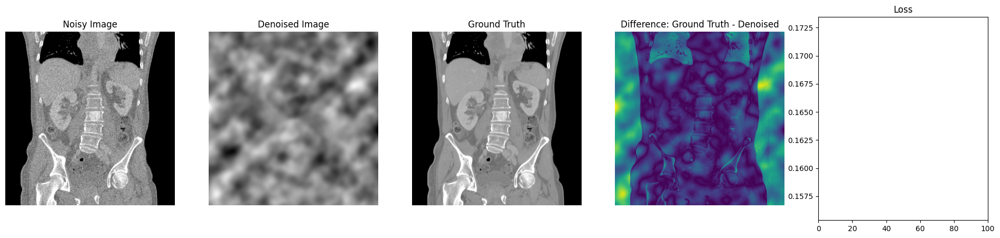

Iteration 20    Loss 0.0251


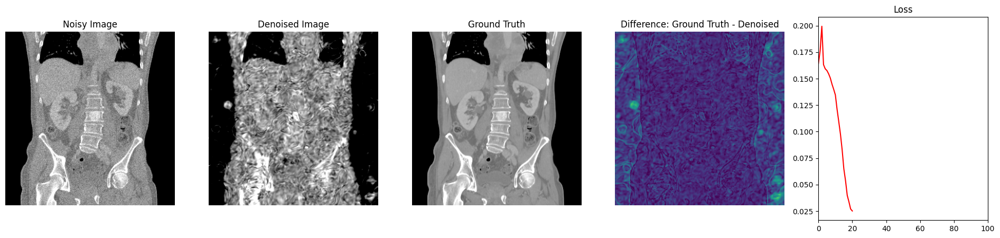

Iteration 40    Loss 0.0060


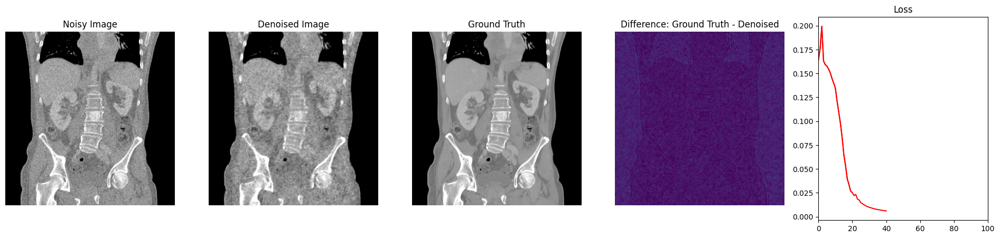

Iteration 60    Loss 0.0038


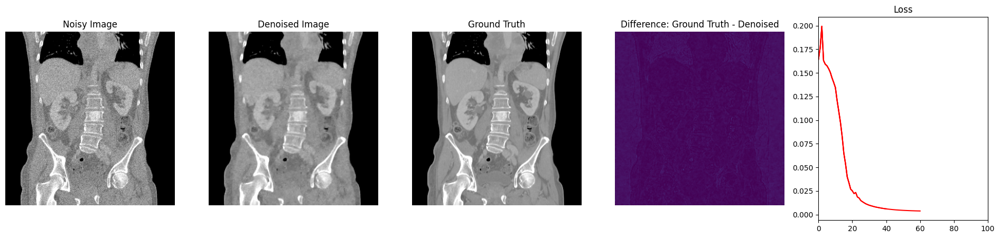

Iteration 80    Loss 0.0039


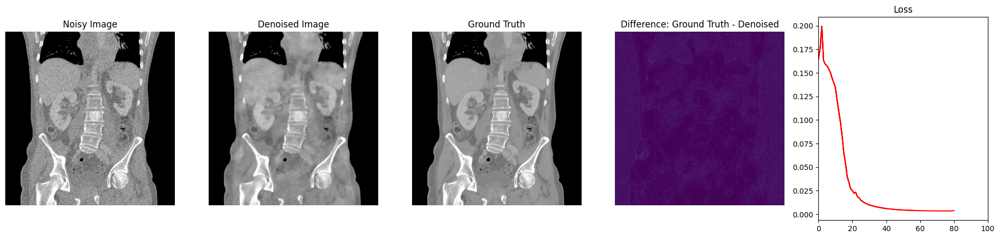

Iteration 99    Loss 0.0034


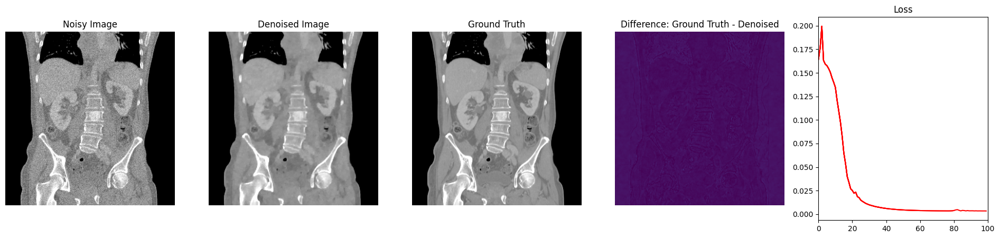

In [40]:
#normalize noisy image by its maximum value to make the optimization easier
scale = noisy_img.max()
noisy_img_normed = noisy_img / scale
noisy_img_normed = noisy_img_normed.cuda()

# Optimization setup
num_iters = 100
lambda_tv = 0.05 # TODO: weighting
lr = 1e-3 #


# Todo: create a 2D grid of coordinates with the same size as the image using `torch.meshgrid` or `torch.nn.functional.affine_grid`
H,W = img.shape
coords = create_grid(H,W).cuda()
# Todo: create a Siren Network with the following settings
# in_features = 2, hidden_features = 256, hidden_layers = 3, out_features = 1
# The Network you have implemented should have ~198401 parameters
denoising_siren = Siren(in_features=2, out_features=1, hidden_ch=256, num_layers=3).cuda()


# Todo: initialize the weights of the network
denoising_siren.apply(weights_init)
# Todo: initialize the optimizer with the parameters of the network and a learning rate of 1e-3
optimizer = torch.optim.Adam(lr=lr, params=denoising_siren.parameters())

# plotting
fig, ax = plt.subplots(1, 5, figsize=(24, 5))
labels = ['Noisy Image', 'Denoised Image', 'Ground Truth', 'Difference: Ground Truth - Denoised', 'Loss']
for i in range(5):
    ax[i].set_title(labels[i])
    if i != 4:
        ax[i].set_axis_off()
ax[4].set_xlim(0, num_iters)


# statistics
running_loss = []

for i in range(num_iters):

    # Todo: reset the gradients of the optimizer
    optimizer.zero_grad()

    # Todo: forward pass of the network
    prediction = denoising_siren(coords)

    # Todo: calculate the loss
    loss_img = F.mse_loss(prediction, noisy_img_normed.reshape(-1,1))
    loss_tv = lambda_tv * TVLoss(prediction.reshape(H,W))
    loss = loss_img + loss_tv

    # Todo: backward pass and update the weights
    loss.backward()
    optimizer.step()

    running_loss.append(loss.item())
    if i % 20 == 0 or i == num_iters - 1:
        print('Iteration %d    Loss %.4f' % (i, loss.item()))
        ax[0].imshow(torch.clamp(noisy_img_normed.detach().cpu().reshape(H, W) * scale, -500, 500), cmap='gray')
        ax[1].imshow(torch.clamp(prediction.detach().cpu().reshape(H, W) * scale, -500, 500), cmap='gray')
        ax[2].imshow(torch.clamp(img, -500, 500), cmap='gray')
        ax[3].imshow((normalize(img) - normalize(prediction.detach().cpu().reshape(H, W) * scale)).abs(), vmin=0, vmax=1)
        ax[4].plot(running_loss, 'r')
        display(fig); plt.close()

plt.show()

# Results Denoising


1.   TV loss for the clean image is 53.97 and for noisy image is 160.
2.   Fixed the noise in images with a TV penalty lambda_tv=0.05. Loss converges to 0.003 and the difference to ground truth is small.



### Task 3: Registration
For the last task, we want to use implicit neural representations to register the following two images.
Instead of fitting an image, the INR is now supposed to fit the deformation field. The loss will be the difference between the fixed image and the moving image, that is warped using the deformation field, and a regularization term.

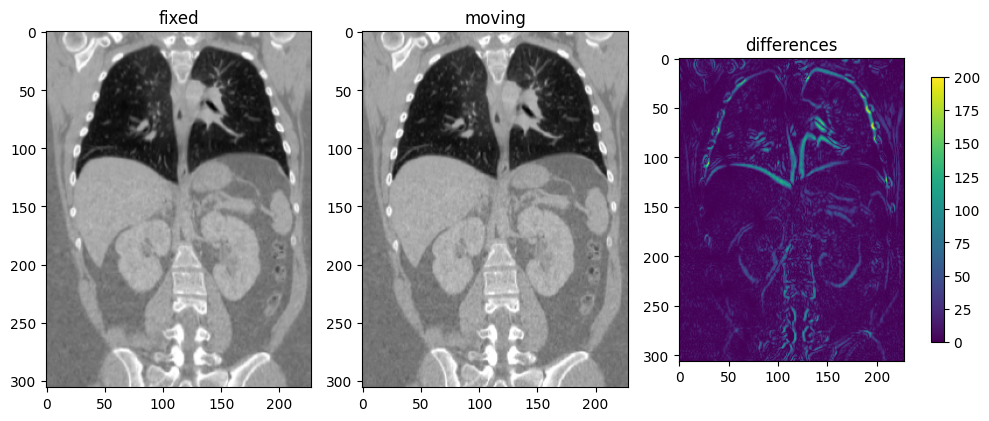

In [41]:
images = torch.load('images_flow.pth')
fixed = images[0:1].unsqueeze(1).cuda()
moving = images[1:2].unsqueeze(1).cuda()
fig, ax = plt.subplots(1, 3, figsize=(10,20))
ax[0].imshow(fixed.cpu().squeeze(), cmap='gray')
ax[0].set_title('fixed')
ax[1].imshow(moving.cpu().squeeze(), cmap='gray')
ax[1].set_title('moving')
dif = ax[2].imshow((moving - fixed).cpu().abs().squeeze(), vmin=0, vmax=200)
ax[2].set_title('differences')
plt.colorbar(dif, fraction=0.05, pad=0.1)
fig.tight_layout()
plt.show()

In [42]:
# function to visualise a deformation field
def showFlow(def_x):
    x = def_x.squeeze().numpy()[0, :, :]
    y = def_x.squeeze().numpy()[1, :, :]
    #show flow map for numpy
    H, W = x.shape
    rho = np.sqrt(x * x + y * y)
    theta = np.arctan2(x, -y)
    theta2 = (-theta + np.pi) / (2.0 * np.pi)
    rho = np.clip(rho / np.percentile(rho, 99), 0, 1)
    hsv = np.stack((theta2, rho, np.ones((H, W))), axis=2)
    rgb = mcolors.hsv_to_rgb(hsv)
    return rgb

Initialise everything needed for the registration task:
- **height and width** parameters $H$, $W$
- the Siren **network**: the network needs to predict a deformation for the x- and y-values, this should be reflected in the number of output features
- **coordinate input** of size $HW \times 2$
- an **identity grid** of size $1\times 1 \times H \times W$ to add to the deformation field for the warping step (you can initialize this the same way as the coordinates)

In [43]:
fixed = fixed.cuda()
moving = moving.cuda()
H,W = fixed.shape[-2:]
# initialize the Siren network (remember to initialise the weights as well)
# set hidden_ch=64 and num_layers=3
net = Siren(in_features=2, out_features=2, hidden_ch=64, num_layers=3).cuda()
net.apply(weights_init)

identity_grid = create_grid(H,W).view(1,H,W,2).cuda()

coords = create_grid(H,W).cuda()


Next, implement the training loop.

The model output should be used to warp the moving image using `F.grid_sample`. To perform the warping step, add the predefined identity grid to your predicted displacement field (use `.view` on the model output).

The loss consists of two parts:
- The mean squared error between fixed and warped image
- The mean of the squared gradient of the deformation field. The gradient can be obtained with `torch.gradient` and stacked with `torch.stack`. Perform this separately for the x and y direction (first and second feature dimension of the model output).
- The parts can be weighted with a factor (Hint: The Smoothness Factor should be weighted stronger than the image similarity)

In the end, you should be able to obtain a smooth displacement field that creates a well fitting warped image.

Iteration 0    Loss 0.1353


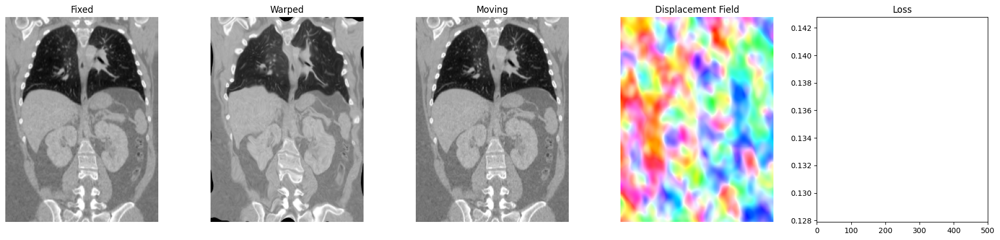

Iteration 100    Loss 0.0029


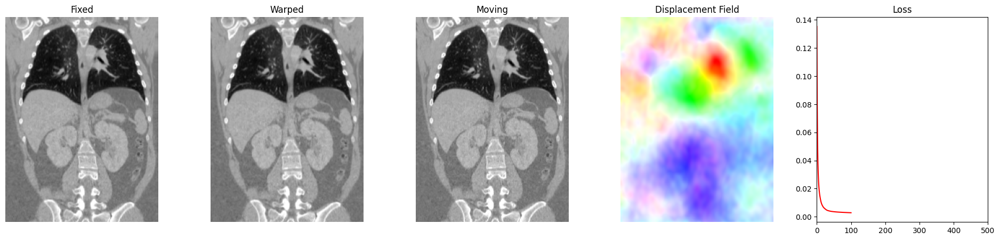

Iteration 200    Loss 0.0023


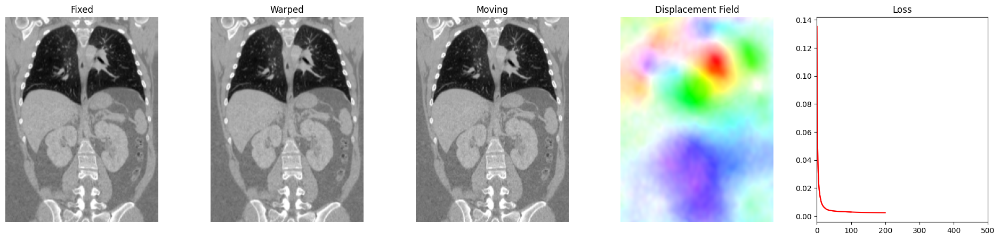

Iteration 300    Loss 0.0022


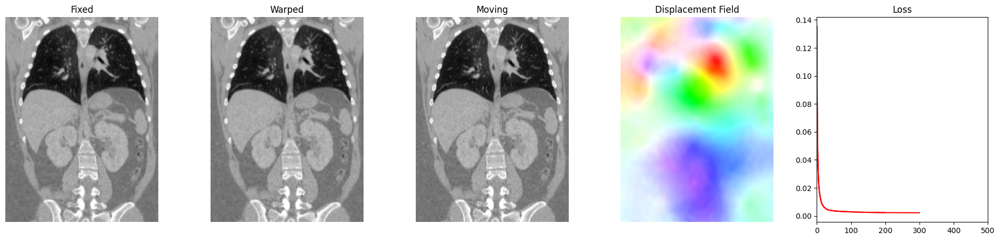

Iteration 400    Loss 0.0022


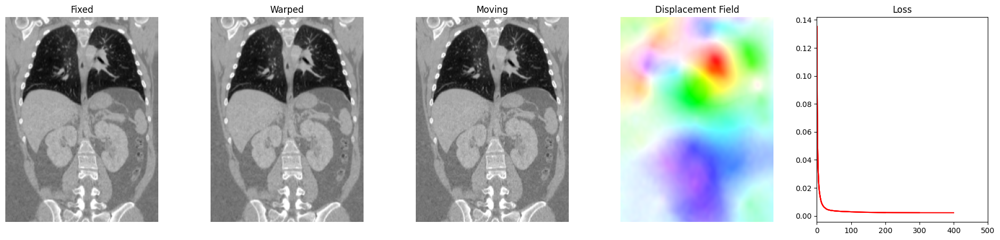

Iteration 499    Loss 0.0022


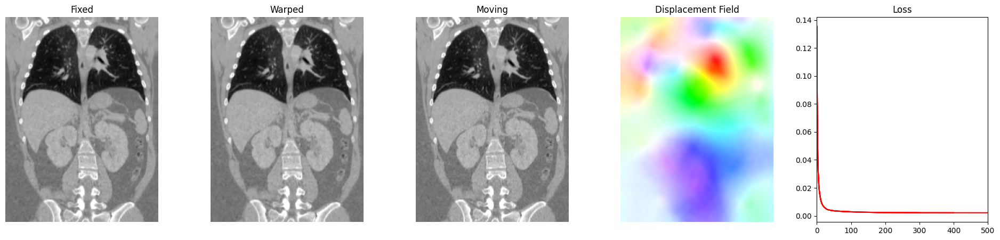

In [44]:
total_steps = 500
steps_til_summary = 100

# TODO: Adam optimizer with learning rate 1e-4
optimizer = torch.optim.Adam(lr=1e-4, params=net.parameters())

lambda_sim = 1.
lambda_smooth = 1e4
img_scale= fixed.max()

# plotting
fig, ax = plt.subplots(1, 5, figsize=(24, 5))
labels = ['Fixed', 'Warped', 'Moving', 'Displacement Field', 'Loss']
for i in range(5):
    ax[i].set_title(labels[i])
    if i != 4:
        ax[i].set_axis_off()
ax[4].set_xlim(0, total_steps)

running_loss = []

for step in range(total_steps):
    # TODO: reset gradient
    optimizer.zero_grad()

    # TODO: forward pass of the network
    model_output = net(coords)

    # TODO: get the prediction
    prediction = identity_grid + model_output.view(1,H,W,2)


    # TODO: warp the image
    warped = F.grid_sample(moving, prediction, align_corners=True)

    # TODO: Compute loss criteria
    loss_sim = F.mse_loss(warped/img_scale, fixed/img_scale)
    disp = model_output.view(H,W,2)
    grad_x = torch.stack(torch.gradient(disp[:,:,0]))
    grad_y = torch.stack(torch.gradient(disp[:,:,1]))
    loss_smooth = torch.mean(grad_x**2) + torch.mean(grad_y**2)
    loss = lambda_sim * loss_sim + lambda_smooth * loss_smooth # Using 'loss' as the final loss variable

    # Create detached versions for plotting *before* backward() is called
    # This ensures they are available after the computation graph is freed.
    if step % steps_til_summary == 0 or step == total_steps - 1:
        model_output_detached = model_output.detach()
        warped_detached = warped.detach()

    # TODO: backpropagation and optimizer step
    loss.backward()
    optimizer.step()


    running_loss.append(loss.item())
    if step % steps_til_summary == 0 or step == total_steps - 1:
        # Use detached versions for display
        rgb = showFlow(model_output_detached.reshape(1,H,W,2).permute(0,3,1,2).cpu())
        print('Iteration %d    Loss %.4f' % (step, loss.item()))
        ax[0].imshow(fixed.detach().cpu().reshape(H, W), cmap='gray')
        ax[1].imshow(warped_detached.cpu().reshape(H, W), cmap='gray')
        ax[2].imshow(moving.detach().cpu().reshape(H, W), cmap='gray')
        ax[3].imshow(rgb)
        ax[4].plot(running_loss, 'r')
        display(fig); plt.close()


# Result Summary


1.   Loss drops from 0.135 to 0.002 ad plateaus after 200 steps.
2.   The warped images matches fixed images well.  
3.   Remaining loss signifies trade off in image similarity and smoothness.
